In [1]:
import os
os.environ["XLA_PYTHON_CLIENT_MEM_FRACTION"] = ".08"
import numpy as np
import tifffile
from skophys.preprocessing import Vectorizer, UnVectorizer
from skophys.sm import NNCCA, NNSM
from skophys.datasets import ARProcessMovie
from sklearn.metrics.pairwise import cosine_similarity
from skimage.transform import downscale_local_mean
from ipywidgets import HBox, VBox
import fastplotlib as fpl
from matplotlib import pyplot as plt
from tqdm import tqdm
from pathlib import Path
import seaborn as sns
from itertools import product

fastplotlib version from git (0.5.0) and __version__ (0.5.1) don't match.
rendercanvas version from git (2.0.0) and __version__ (2.0.3) don't match.
Unable to find extension: VK_EXT_swapchain_colorspace


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Valid,Device,Type,Backend,Driver
✅ (default),AMD RADV POLARIS10 (ACO),DiscreteGPU,Vulkan,Mesa 20.3.5 (ACO)
❗ limited,"llvmpipe (LLVM 11.0.1, 256 bits)",CPU,Vulkan,Mesa 20.3.5 (LLVM 11.0.1)
✅,NVIDIA GeForce RTX 3080,DiscreteGPU,Vulkan,530.30.02
❌,"Radeon RX 570 Series (POLARIS10, DRM 3.40.0, 5.10.0-21-amd64, LLVM 11.0.1)",Unknown,OpenGL,4.6 (Core Profile) Mesa 20.3.5


pygfx version from git (0.9.0) and __version__ (0.10.0) don't match.


In [2]:
%matplotlib inline

In [3]:
movie = tifffile.memmap("../demo_movie_mcorr.tiff")

In [4]:
movie.shape

(2000, 60, 80)

In [5]:
movie = downscale_local_mean(movie, factors=(1, 2, 2))

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
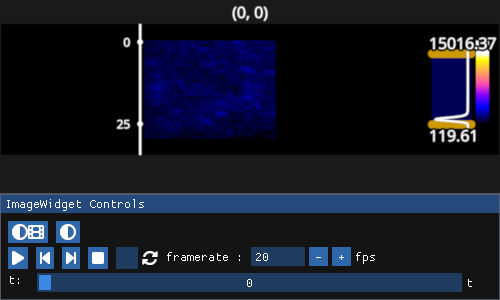

In [6]:
iw = fpl.ImageWidget(movie, cmap="gnuplot2")#, frame_apply={0: lambda f: f - movie_mean})
iw.show()

In [46]:
model = NNCCA(lag=1, lag_step=1)

In [47]:
model.pre_initialize(movie, max_k=32, k=12)

creating H
Whitening H
computing covariance
performing nnSVD


In [34]:
model.pre_init_arrays.k

12

RFBOutputContext()

JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
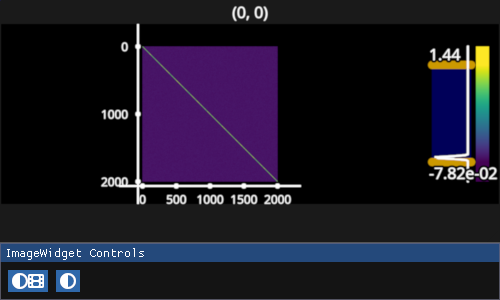

In [35]:
fpl.ImageWidget(model.cov_init, cmap="viridis").show()

<Axes: >

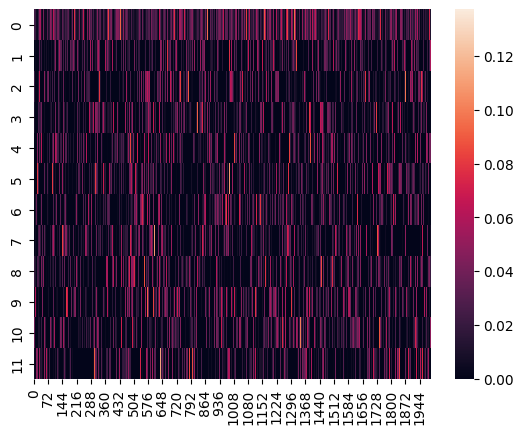

In [36]:
sns.heatmap(model.pre_init_arrays.Y)

In [37]:
err_log, Ys, Ws = model.initialize(max_iter=5_000, keep_iteration_results=True, eta=0.1, inertia=1e-3, error_threshold=0.05)

 30%|████████████████████▌                                               | 1512/5000 [00:07<00:18, 193.52it/s]


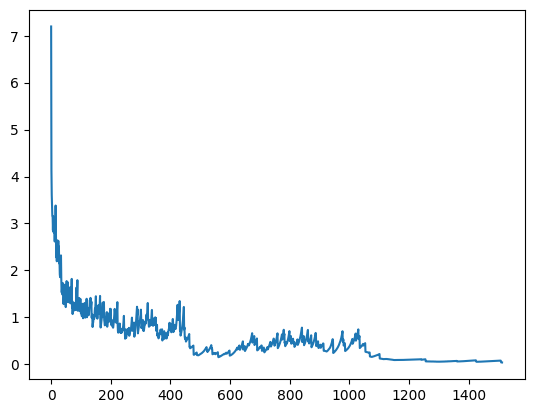

In [38]:
plt.plot(err_log)

In [39]:
err_log[-1]

0.03843478485941887

RFBOutputContext()

JupyterRenderCanvas(css_height='300.0px', css_width='1500.0px')
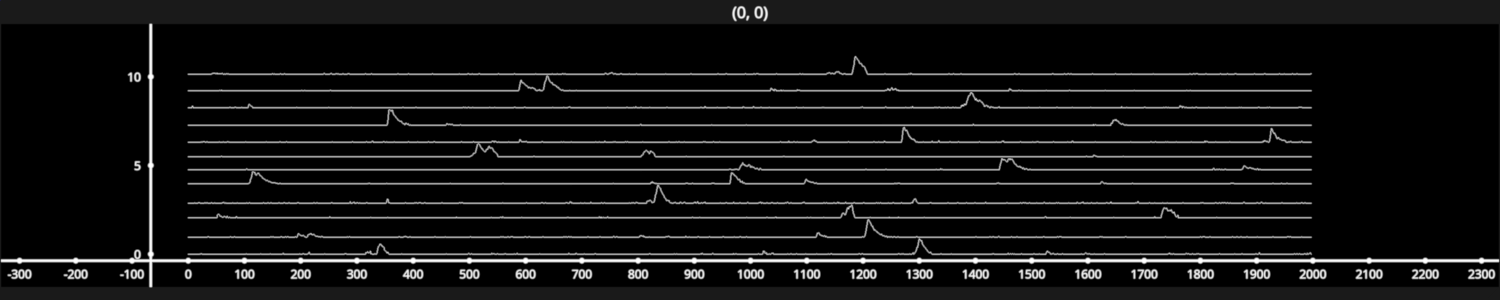

In [40]:
fig = fpl.Figure(size=(1500, 300))

fig[0, 0].add_line_stack(model.init_arrays.Y / model.init_arrays.Y.max(), separation=0.1, thickness=1)

for subplot in fig:
    subplot.toolbar = False

fig.show(maintain_aspect=False)

In [41]:
images, titles = list(), list(),
for k_i, l_i in product(range(model.init_arrays.k), range(model.lag)):
    images.append(model.unvec.transform(model.init_arrays.W[k_i, model.lag_slices[l_i]].T))
    titles.append(f"component: {k_i}, lag: {l_i}")

RFBOutputContext()

JupyterRenderCanvas(css_height='1000.0px', css_width='800.0px')
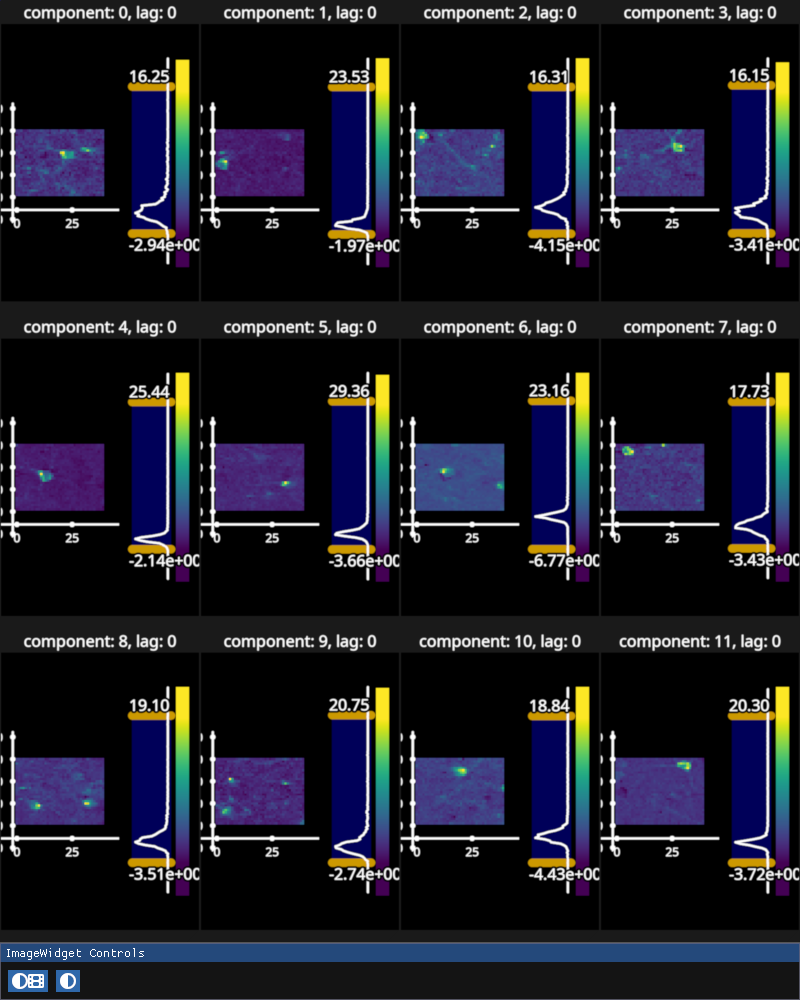

In [43]:
iw_W2 = fpl.ImageWidget(
    images,
    cmap="viridis",
    names=titles,
    figure_kwargs={"size": (800, 1000)},
)

for subplot in iw_W2.figure:
    subplot.toolbar = False

# for g in iw_W2.managed_graphics:
#     g.vmin = 0

iw_W2.show()